
# Simple HH E–I model for DBS / beta–gamma exploration

This notebook is intentionally simple:

- 1 excitatory HH neuron
- 1 inhibitory HH neuron
- E→I AMPA
- I→E GABA
- tonic background current + optional weak Poisson AMPA background
- DBS pulse train applied directly to one cell
- a crude **LFP proxy** from synaptic current onto the E neuron

The workflow is:

1. **Tune DBS-OFF dynamics first** so the pair has a beta peak.
2. Inspect the raw E/I membrane traces.
3. Inspect the LFP proxy in time and frequency.
4. Only then turn on DBS and step amplitude from 0 to 10.
5. Look for entrainment and, at high drive, possible HH depolarization block.

The LFP here is only a proxy. With one E neuron it should be interpreted as a convenient signal for tuning, not as a literal ECoG/LFP model.


In [1]:

# If needed:
# %pip install brian2 scipy matplotlib numpy pandas

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

from brian2 import *


INFO       Cache size for target 'cython': 2364 MB.
You can call clear_cache('cython') to delete all files from the cache or manually delete files in the '/home/vincent/.cython/brian_extensions' directory. [brian2]



## 1. Parameters

For now, change parameters **only in this cell**.

The most important resting-beta tuning knobs are:

- `I_TONIC_E`
- `I_TONIC_I`
- `W_EI`
- `W_IE`
- `TAU_GABA`

Start by tuning the resting state. Do not tune the model to the 83 Hz peak yet.


In [17]:

# ---------------------------
# Numerical settings
# ---------------------------
DT = 0.02*ms
RECORD_DT = 0.1*ms

# ---------------------------
# HH membrane parameters
# approximately classical HH scaled to a ~20,000 um^2 cell
# ---------------------------
CM = 200*pF
G_NA = 24*uS
G_K  = 7.2*uS
G_L  = 60*nS

E_NA = 50*mV
E_K  = -77*mV
E_L  = -54.4*mV

# ---------------------------
# Synapses
# ---------------------------
E_AMPA = 0*mV
E_GABA = -80*mV

TAU_AMPA = 3*ms
TAU_GABA = 15*ms

# E -> I AMPA
W_EI = 80*nS

# I -> E GABA
W_IE = 180*nS

SYN_DELAY = 1*ms

# ---------------------------
# Tonic background
# ---------------------------
I_TONIC_E = 1.8*nA
I_TONIC_I = 0.9*nA

# Optional weak Poisson AMPA background
USE_POISSON_BACKGROUND = True
BG_N = 200
BG_RATE = 2*Hz
BG_WEIGHT = 0.4*nS

# ---------------------------
# DBS
# ---------------------------
PULSE_WIDTH = 0.06*ms

# IMPORTANT:
# This is NOT a physical conversion from clinical mA to somatic current.
# It is a free phenomenological gain that we will eventually calibrate.
DBS_GAIN_NA_PER_MA = 2.0

# Apply DBS directly to E for now because we want to inspect HH saturation.
# Later test I or both as sensitivity analyses.
DBS_TARGET_E = 1.0
DBS_TARGET_I = 0.0

# Rest and stimulation durations
REST_DURATION = 10*second
SETTLE = 2*second
SEGMENT_DURATION = 3*second

AMP_LEVELS_MA = np.arange(0, 11, 1)



## 2. Hodgkin–Huxley equations

There is no artificial firing-rate saturation here. If the E neuron is driven too hard, sodium inactivation (`h`) and potassium activation can naturally produce reduced firing / depolarization block.


In [10]:

eqs = r'''
dv/dt = (
      G_NA*m**3*h*(E_NA-v)
    + G_K*n**4*(E_K-v)
    + G_L*(E_L-v)
    + gA*(E_AMPA-v)
    + gG*(E_GABA-v)
    + I_tonic
    + I_dbs
    )/CM : volt

dm/dt = alpha_m*(1-m) - beta_m*m : 1
dh/dt = alpha_h*(1-h) - beta_h*h : 1
dn/dt = alpha_n*(1-n) - beta_n*n : 1

alpha_m = 1.0/exprel(-(v + 40*mV)/(10*mV))/ms : Hz
beta_m  = 4.0*exp(-(v + 65*mV)/(18*mV))/ms : Hz

alpha_h = 0.07*exp(-(v + 65*mV)/(20*mV))/ms : Hz
beta_h  = 1.0/(1.0 + exp(-(v + 35*mV)/(10*mV)))/ms : Hz

alpha_n = 0.1/exprel(-(v + 55*mV)/(10*mV))/ms : Hz
beta_n  = 0.125*exp(-(v + 65*mV)/(80*mV))/ms : Hz

dgA/dt = -gA/TAU_AMPA : siemens
dgG/dt = -gG/TAU_GABA : siemens

I_tonic : amp
dbs_target : 1

I_dbs = dbs_target * stim_ta(t) : amp
'''



## 3. Simulation functions

`run_rest()` is the one to use first.

`run_dbs_staircase()` steps the DBS label through 0, 1, 2, ..., 10 mA.


In [18]:

def make_zero_stim(duration):
    n = int(np.ceil(float(duration/DT)))
    return TimedArray(np.zeros(n)*nA, dt=DT)


def make_dbs_staircase(freq_hz):
    dt_s = float(DT/second)
    pw_s = float(PULSE_WIDTH/second)
    settle_s = float(SETTLE/second)
    seg_s = float(SEGMENT_DURATION/second)

    n_settle = int(round(settle_s/dt_s))
    n_seg = int(round(seg_s/dt_s))
    n_total = n_settle + len(AMP_LEVELS_MA)*n_seg

    current_nA = np.zeros(n_total)

    period_s = 1.0/freq_hz

    for j, amp_mA in enumerate(AMP_LEVELS_MA):
        i0 = n_settle + j*n_seg
        i1 = i0 + n_seg

        local_t = np.arange(n_seg)*dt_s
        pulse_mask = np.mod(local_t, period_s) < pw_s

        current_nA[i0:i1] = (
            amp_mA * DBS_GAIN_NA_PER_MA * pulse_mask
        )

    return TimedArray(current_nA*nA, dt=DT), n_total*DT


def build_pair(stim_ta):
    namespace = dict(
        CM=CM,
        G_NA=G_NA,
        G_K=G_K,
        G_L=G_L,
        E_NA=E_NA,
        E_K=E_K,
        E_L=E_L,
        E_AMPA=E_AMPA,
        E_GABA=E_GABA,
        TAU_AMPA=TAU_AMPA,
        TAU_GABA=TAU_GABA,
        stim_ta=stim_ta,
    )

    G = NeuronGroup(
        2,
        eqs,
        threshold='v > 0*mV',
        refractory=2*ms,
        method='rk4',
        namespace=namespace
    )

    # 0 = E, 1 = I
    G.v = -65*mV
    G.m = 0.0529
    G.h = 0.596
    G.n = 0.318

    G.gA = 0*nS
    G.gG = 0*nS

    G.I_tonic = [I_TONIC_E, I_TONIC_I]
    G.dbs_target = [DBS_TARGET_E, DBS_TARGET_I]

    # E -> I
    S_EI = Synapses(
        G, G,
        on_pre='gA_post += W_EI',
        namespace={'W_EI': W_EI}
    )
    S_EI.connect(i=0, j=1)
    S_EI.delay = SYN_DELAY

    # I -> E
    S_IE = Synapses(
        G, G,
        on_pre='gG_post += W_IE',
        namespace={'W_IE': W_IE}
    )
    S_IE.connect(i=1, j=0)
    S_IE.delay = SYN_DELAY

    bg = None
    if USE_POISSON_BACKGROUND:
        bg = PoissonInput(
            G, 'gA',
            N=BG_N,
            rate=BG_RATE,
            weight=BG_WEIGHT
        )

    M = StateMonitor(
        G,
        ['v', 'gA', 'gG', 'h', 'n', 'm', 'I_dbs'],
        record=True,
        dt=RECORD_DT
    )

    Sp = SpikeMonitor(G)

    objects = [G, S_EI, S_IE, M, Sp]
    if bg is not None:
        objects.append(bg)

    net = Network(*objects)
    return net, G, M, Sp


def package_result(M, Sp, freq_hz=None):
    t = np.asarray(M.t/second)

    vE = M.v[0]
    vI = M.v[1]

    I_AMPA_E = M.gA[0]*(E_AMPA - vE)
    I_GABA_E = M.gG[0]*(E_GABA - vE)

    # Very simple LFP proxy:
    # negative total synaptic current onto E
    lfp = -np.asarray((I_AMPA_E + I_GABA_E)/nA)

    return {
        'freq_hz': freq_hz,
        't_s': t,
        'vE_mV': np.asarray(vE/mV),
        'vI_mV': np.asarray(vI/mV),
        'hE': np.asarray(M.h[0]),
        'nE': np.asarray(M.n[0]),
        'mE': np.asarray(M.m[0]),
        'I_AMPA_E_nA': np.asarray(I_AMPA_E/nA),
        'I_GABA_E_nA': np.asarray(I_GABA_E/nA),
        'I_DBS_E_nA': np.asarray(M.I_dbs[0]/nA),
        'lfp': lfp,
        'spike_t_s': np.asarray(Sp.t/second),
        'spike_i': np.asarray(Sp.i),
    }


def run_rest(seed_value=1):
    start_scope()
    seed(seed_value)
    defaultclock.dt = DT

    stim_ta = make_zero_stim(REST_DURATION)
    net, G, M, Sp = build_pair(stim_ta)
    net.run(REST_DURATION)

    return package_result(M, Sp)


def run_dbs_staircase(freq_hz=55.0, seed_value=1):
    start_scope()
    seed(seed_value)
    defaultclock.dt = DT

    stim_ta, total_duration = make_dbs_staircase(freq_hz)
    net, G, M, Sp = build_pair(stim_ta)
    net.run(total_duration, report='text')

    return package_result(M, Sp, freq_hz=freq_hz)



# PART A — Tune the resting beta rhythm first


In [19]:

rest = run_rest(seed_value=1)



## 4. First look: raw neuron time series

Always look at the neurons before looking at a spectrogram.


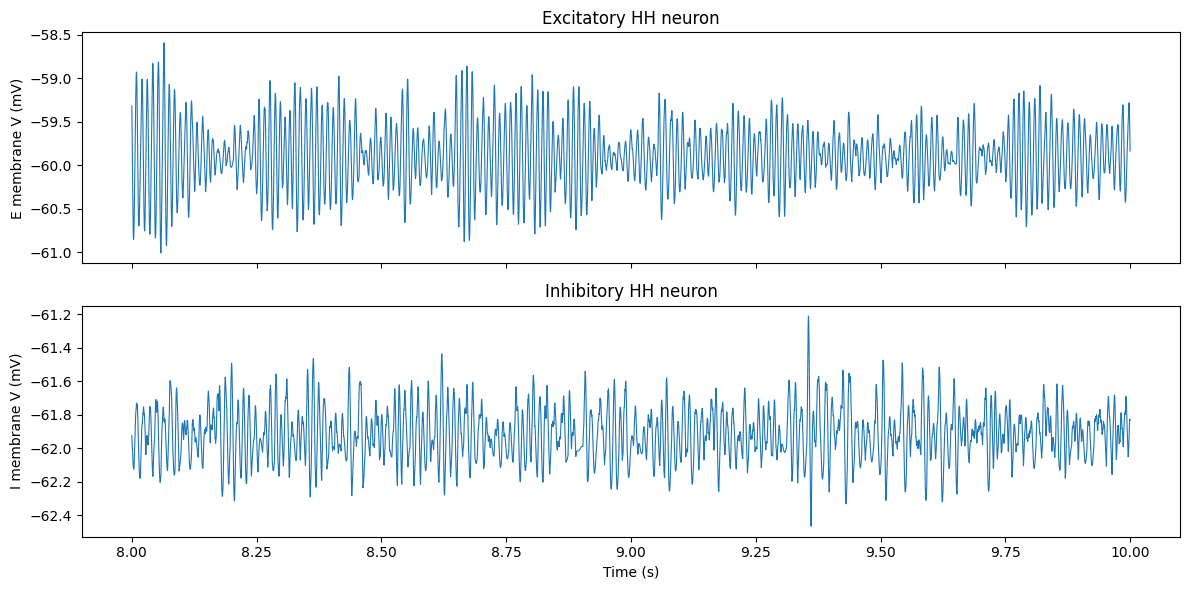

In [20]:

# Show the last 2 seconds
t0 = REST_DURATION/second - 2
mask = rest['t_s'] >= t0

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

ax[0].plot(rest['t_s'][mask], rest['vE_mV'][mask], lw=0.8)
ax[0].set_ylabel('E membrane V (mV)')
ax[0].set_title('Excitatory HH neuron')

ax[1].plot(rest['t_s'][mask], rest['vI_mV'][mask], lw=0.8)
ax[1].set_ylabel('I membrane V (mV)')
ax[1].set_xlabel('Time (s)')
ax[1].set_title('Inhibitory HH neuron')

plt.tight_layout()
plt.show()



## 5. LFP proxy in the time domain

The LFP proxy is the negative of the total AMPA + GABA synaptic current onto the E neuron.

I also plot the two synaptic-current components separately so we can see what generates the oscillation.


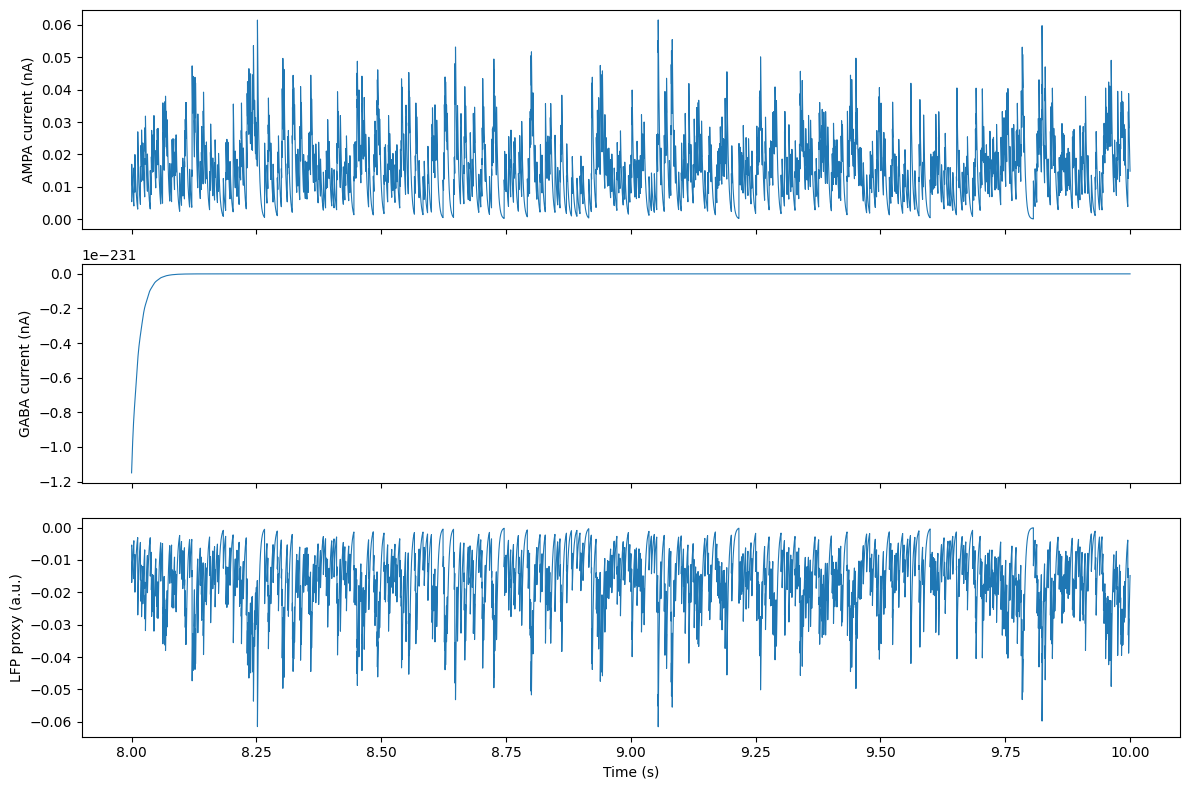

In [15]:

mask = rest['t_s'] >= t0

fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

ax[0].plot(rest['t_s'][mask], rest['I_AMPA_E_nA'][mask], lw=0.8)
ax[0].set_ylabel('AMPA current (nA)')

ax[1].plot(rest['t_s'][mask], rest['I_GABA_E_nA'][mask], lw=0.8)
ax[1].set_ylabel('GABA current (nA)')

ax[2].plot(rest['t_s'][mask], rest['lfp'][mask], lw=0.8)
ax[2].set_ylabel('LFP proxy (a.u.)')
ax[2].set_xlabel('Time (s)')

plt.tight_layout()
plt.show()



## 6. Resting PSD

This is the key tuning plot.

Before moving to DBS, we want a clear peak in the patient's beta range.


Peak frequency between 8-40 Hz: 9.75 Hz


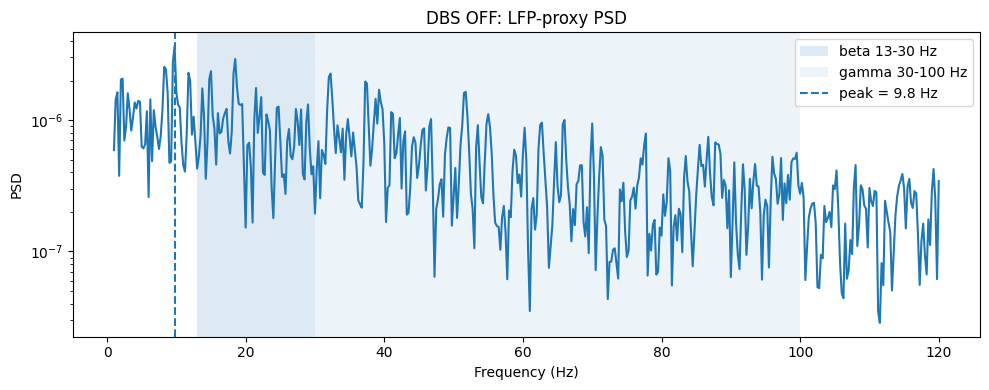

In [16]:

fs = 1.0/float(RECORD_DT/second)

# Ignore first 2 seconds
mask = rest['t_s'] >= 2.0
x = rest['lfp'][mask]
x = x - x.mean()

f, pxx = signal.welch(
    x,
    fs=fs,
    nperseg=min(len(x), int(4*fs))
)

use = (f >= 1) & (f <= 120)
peak_band = (f >= 8) & (f <= 40)

peak_hz = f[peak_band][np.argmax(pxx[peak_band])]
print(f'Peak frequency between 8-40 Hz: {peak_hz:.2f} Hz')

plt.figure(figsize=(10, 4))
plt.semilogy(f[use], pxx[use])
plt.axvspan(13, 30, alpha=0.15, label='beta 13-30 Hz')
plt.axvspan(30, 100, alpha=0.08, label='gamma 30-100 Hz')
plt.axvline(peak_hz, ls='--', label=f'peak = {peak_hz:.1f} Hz')
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD')
plt.title('DBS OFF: LFP-proxy PSD')
plt.legend()
plt.tight_layout()
plt.show()



### Resting-beta tuning rule

If the peak is wrong:

- **too fast** → increase `TAU_GABA`, increase inhibition, or reduce tonic drive
- **too slow** → decrease `TAU_GABA`, weaken inhibition, or increase tonic drive
- **no stable rhythm** → adjust `I_TONIC_E`, `I_TONIC_I`, `W_EI`, `W_IE`
- **too noisy** → temporarily set `USE_POISSON_BACKGROUND = False`
- once the deterministic rhythm works, turn weak Poisson input back on

Do not proceed until this looks reasonable.



# PART B — DBS amplitude staircase

After the resting state is tuned, run 55 Hz DBS.

The clinical amplitude labels are 0–10 mA, but the conversion to somatic current is deliberately represented by the free parameter `DBS_GAIN_NA_PER_MA`.


In [ ]:

dbs55 = run_dbs_staircase(freq_hz=55.0, seed_value=1)



## 7. Raw neuron traces at selected DBS amplitudes

This lets us see what actually happens to the HH neurons at 0, 5, and 10 mA before interpreting frequency-domain plots.


In [ ]:

def amplitude_window(amp_mA):
    j = int(np.where(AMP_LEVELS_MA == amp_mA)[0][0])
    start = float(SETTLE/second) + j*float(SEGMENT_DURATION/second)
    stop  = start + float(SEGMENT_DURATION/second)
    return start, stop


for amp in [0, 5, 10]:
    start, stop = amplitude_window(amp)

    # show last 0.5 s of this amplitude block
    t0 = stop - 0.5
    mask = (dbs55['t_s'] >= t0) & (dbs55['t_s'] < stop)

    fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)

    ax[0].plot(dbs55['t_s'][mask], dbs55['vE_mV'][mask], lw=0.7)
    ax[0].set_ylabel('E V (mV)')
    ax[0].set_title(f'55 Hz DBS, amplitude label = {amp} mA')

    ax[1].plot(dbs55['t_s'][mask], dbs55['vI_mV'][mask], lw=0.7)
    ax[1].set_ylabel('I V (mV)')
    ax[1].set_xlabel('Time (s)')

    plt.tight_layout()
    plt.show()



## 8. LFP proxy across the entire amplitude staircase


In [ ]:

plt.figure(figsize=(14, 4))
plt.plot(dbs55['t_s'], dbs55['lfp'], lw=0.5)
plt.xlabel('Time (s)')
plt.ylabel('LFP proxy (a.u.)')
plt.title('55 Hz DBS: full LFP-proxy time series')

# mark amplitude transitions
for j, amp in enumerate(AMP_LEVELS_MA):
    x = float(SETTLE/second) + j*float(SEGMENT_DURATION/second)
    plt.axvline(x, lw=0.5, alpha=0.4)
    plt.text(x+0.05, plt.ylim()[1]*0.8, f'{amp}', fontsize=8)

plt.tight_layout()
plt.show()



## 9. Zoomed LFP at 0, 5, and 10 mA

This is useful for distinguishing:

- endogenous beta
- pulse-locked activity
- high-drive saturation / block


In [ ]:

for amp in [0, 5, 10]:
    start, stop = amplitude_window(amp)

    t0 = stop - 0.5
    mask = (dbs55['t_s'] >= t0) & (dbs55['t_s'] < stop)

    plt.figure(figsize=(12, 3))
    plt.plot(dbs55['t_s'][mask], dbs55['lfp'][mask], lw=0.8)
    plt.xlabel('Time (s)')
    plt.ylabel('LFP proxy')
    plt.title(f'55 Hz DBS: LFP proxy at {amp} mA')
    plt.tight_layout()
    plt.show()



## 10. PSD at selected DBS amplitudes

Before the spectrogram, compare spectra from individual amplitude blocks.


In [ ]:

fs = 1.0/float(RECORD_DT/second)

plt.figure(figsize=(10, 5))

for amp in [0, 2, 5, 8, 10]:
    start, stop = amplitude_window(amp)

    # discard first 0.5 s after each amplitude change
    mask = (
        (dbs55['t_s'] >= start + 0.5)
        & (dbs55['t_s'] < stop)
    )

    x = dbs55['lfp'][mask]
    x = x - x.mean()

    f, pxx = signal.welch(
        x,
        fs=fs,
        nperseg=min(len(x), int(2*fs))
    )

    keep = (f >= 5) & (f <= 140)
    plt.semilogy(f[keep], pxx[keep], label=f'{amp} mA')

plt.axvline(27.5, ls='--', lw=1, label='55/2 = 27.5 Hz')
plt.axvline(55.0, ls='--', lw=1, label='55 Hz')
plt.axvline(82.5, ls='--', lw=1, label='3×55/2 = 82.5 Hz')

plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD')
plt.title('55 Hz DBS: PSD at selected amplitudes')
plt.legend(ncol=2)
plt.tight_layout()
plt.show()



## 11. Spectrogram

Now that we have looked at the neurons and the LFP time series, make the spectrogram.


In [ ]:

fs = 1.0/float(RECORD_DT/second)

x = dbs55['lfp'] - np.mean(dbs55['lfp'])

f, tt, Sxx = signal.spectrogram(
    x,
    fs=fs,
    nperseg=int(1.5*fs),
    noverlap=int(1.3*fs),
    detrend='constant',
    scaling='density',
    mode='psd'
)

keep = (f >= 5) & (f <= 140)

plt.figure(figsize=(14, 6))
plt.pcolormesh(
    tt,
    f[keep],
    10*np.log10(Sxx[keep] + 1e-18),
    shading='auto'
)

plt.axhline(27.5, ls='--', lw=1, label='f/2 = 27.5 Hz')
plt.axhline(55.0, ls='--', lw=1, label='f = 55 Hz')
plt.axhline(82.5, ls='--', lw=1, label='3f/2 = 82.5 Hz')

for j, amp in enumerate(AMP_LEVELS_MA):
    xline = float(SETTLE/second) + j*float(SEGMENT_DURATION/second)
    plt.axvline(xline, lw=0.5, alpha=0.4)

plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.title('Neural LFP proxy — 55 Hz DBS amplitude staircase')
plt.colorbar(label='Power (dB, arbitrary)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()



## 12. Simple HH saturation / depolarization-block diagnostics

A useful signature of true high-drive depolarization block would be:

- firing rate stops increasing or decreases
- mean membrane voltage stays relatively depolarized
- sodium inactivation variable `h` becomes small

This is more informative than calling any high-frequency response "saturation."


In [ ]:

rows = []

for amp in AMP_LEVELS_MA:
    start, stop = amplitude_window(amp)

    # discard transition
    start2 = start + 0.5

    time_mask = (
        (dbs55['t_s'] >= start2)
        & (dbs55['t_s'] < stop)
    )

    spike_mask = (
        (dbs55['spike_i'] == 0)
        & (dbs55['spike_t_s'] >= start2)
        & (dbs55['spike_t_s'] < stop)
    )

    duration = stop - start2
    e_rate = np.sum(spike_mask)/duration

    rows.append({
        'amp_mA': amp,
        'E_rate_Hz': e_rate,
        'mean_VE_mV': np.mean(dbs55['vE_mV'][time_mask]),
        'mean_hE': np.mean(dbs55['hE'][time_mask]),
    })

summary = pd.DataFrame(rows)
display(summary)

fig, ax = plt.subplots(3, 1, figsize=(8, 8), sharex=True)

ax[0].plot(summary['amp_mA'], summary['E_rate_Hz'], 'o-')
ax[0].set_ylabel('E firing rate (Hz)')

ax[1].plot(summary['amp_mA'], summary['mean_VE_mV'], 'o-')
ax[1].set_ylabel('Mean E V (mV)')

ax[2].plot(summary['amp_mA'], summary['mean_hE'], 'o-')
ax[2].set_ylabel('Mean Na h')
ax[2].set_xlabel('DBS amplitude label (mA)')

plt.tight_layout()
plt.show()



# PART C — Repeat at 80 Hz

Once 55 Hz is understood, simply run the same protocol at 80 Hz.


In [ ]:

# dbs80 = run_dbs_staircase(freq_hz=80.0, seed_value=1)

# Then reuse the exact same plotting cells by replacing:
#     dbs55
# with
#     dbs80
#
# For 80 Hz, the reference frequencies are:
#     f/2  = 40 Hz
#     f    = 80 Hz
#     3f/2 = 120 Hz



## What to tune next

For now I would keep the model this simple.

### Step 1
Get a stable resting beta peak with DBS OFF.

### Step 2
Freeze the resting parameters.

### Step 3
Reduce or increase `DBS_GAIN_NA_PER_MA` until stimulation perturbs the rhythm gradually instead of immediately forcing 1:1 locking.

### Step 4
Check whether 55 Hz stimulation creates a genuine 27.5, 55, or 82.5 Hz neural response.

### Step 5
Only after this works, move to a larger spatial E/I network and electrode-distance effects.
